# Super cool experiment

# Super cool experiment

In [2]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt

## Import packages

In [17]:
outpath = "/media/sergio/Meninges/troutpy/xenium_msbrain_300/msbrain.zarr"
sdata=sd.read_zarr(outpath)

In [18]:
print(sdata.coordinate_systems)
#print(sdata['table'].coordinate_system)  # coordinate system of the table

['global']


In [5]:
from spatialdata.transformations import get_transformation

# Get spatial coordinates (Nx2 array)
local_coords = sdata['table'].obsm['spatial']

print(sdata.coordinate_systems)
print(
#    get_transformation(sdata["table"]),
    get_transformation(sdata["morphology_focus"]),
    get_transformation(sdata["nucleus_boundaries"]),
)



['global']
Identity  Scale (x, y)
    [4.70588235 4.70588235]


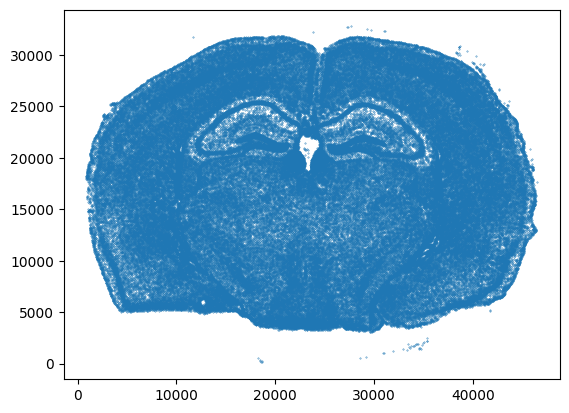

In [6]:
spat=[g[0]*4.705 for g in sdata['table'].obsm['spatial']]
spat2=[g[1]*4.705 for g in sdata['table'].obsm['spatial']]
plt.scatter(spat,spat2,s=0.1)

In [19]:
cropped_sdata = sdata.query.bounding_box(
    axes=["x", "y"],
    min_coordinate=[15000, 16000],
    max_coordinate=[18000, 30000],
    target_coordinate_system="global",
)


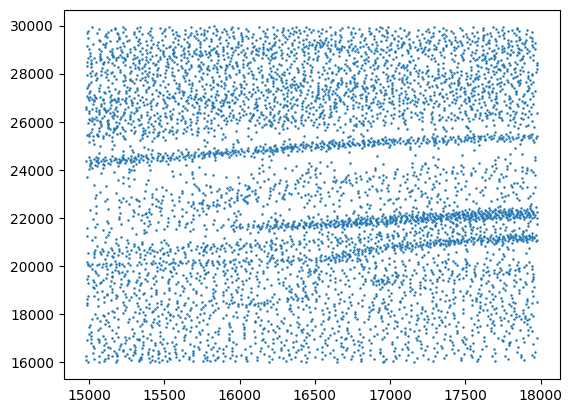

In [20]:
spat=[g[0]*4.7 for g in cropped_sdata['table'].obsm['spatial']]
spat2=[g[1]*4.7 for g in cropped_sdata['table'].obsm['spatial']]
plt.scatter(spat,spat2,s=0.6)

In [21]:
sdata=cropped_sdata

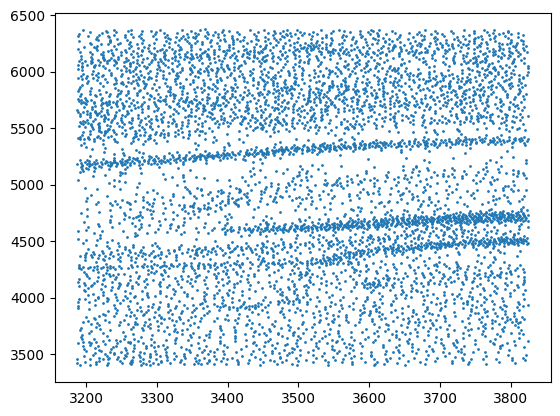

In [22]:
spat=[g[0] for g in sdata['table'].obsm['spatial']]
spat2=[g[1] for g in sdata['table'].obsm['spatial']]
plt.scatter(spat,spat2,s=1)

In [23]:
transcripts=sdata['transcripts'].compute()
transcripts.reset_index(drop=True,inplace=True)
sdata['transcripts']=sd.models.PointsModel.parse(transcripts)

# Cell type identification

(6139, 248)


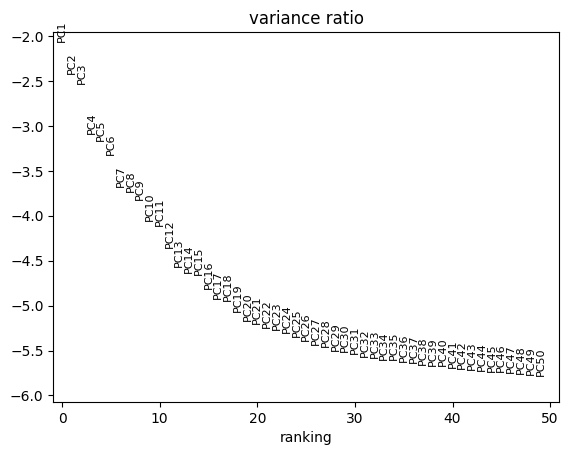

(6136, 248)


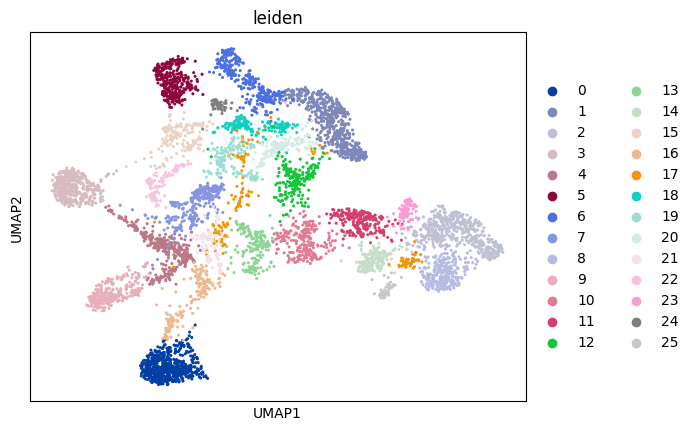

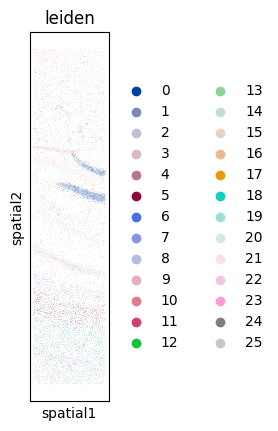

In [24]:
adata = sdata["table"]
#sc.pp.subsample(adata,0.1)
print(adata.shape)
adata.raw = adata.copy()
sc.pp.filter_cells(adata, min_genes=10)
sc.pp.filter_genes(adata, min_cells=3)
adata.layers["raw"] = adata.X.copy()
sc.pp.normalize_total(adata)
# Logarithmize the data
sc.pp.log1p(adata)
sc.tl.pca(adata)
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)
sc.pp.neighbors(adata)
sc.tl.umap(adata)
print(adata.shape)
sc.tl.leiden(adata, key_added="leiden")
sc.pl.umap(adata,color='leiden')
sc.pl.spatial(adata,color='leiden',spot_size=5)

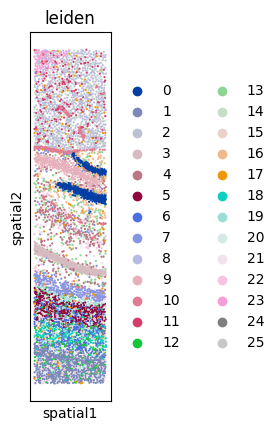

In [25]:
sc.pl.spatial(adata,color='leiden',spot_size=20)

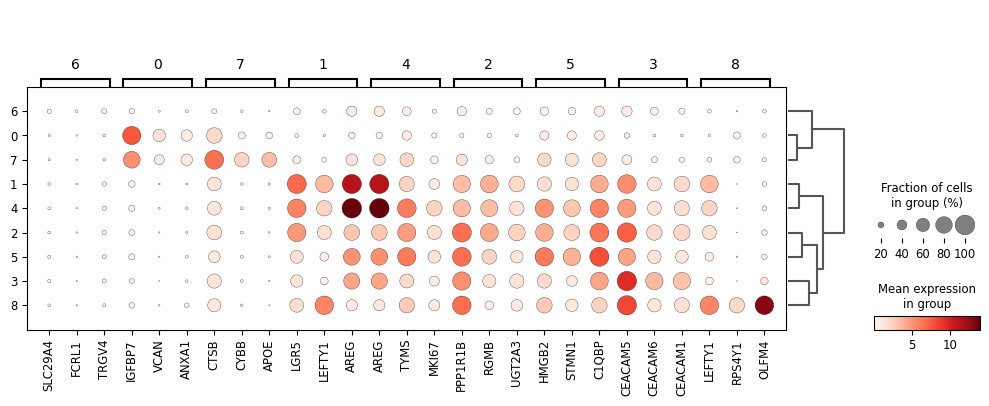

In [27]:
sc.tl.dendrogram(adata,groupby='leiden')
sc.tl.rank_genes_groups(adata,groupby='leiden')
sc.pl.rank_genes_groups_dotplot(adata,groupby='leiden',n_genes=3)

In [26]:
outpath = "/media/sergio/Meninges/troutpy/xenium_msbrain_300/msbrain_silvia_roi.zarr"
sdata.write(outpath,overwrite=True)

INFO     The SpatialData object is not self-contained (i.e. it contains some elements that are Dask-backed from    
         locations outside /media/sergio/Meninges/troutpy/xenium_msbrain_300/msbrain_silvia_roi.zarr). Please see  
         the documentation of `is_self_contained()` to understand the implications of working with SpatialData     
         objects that are not self-contained.                                                                      
INFO     The Zarr backing store has been changed from None the new file path:                                      
         /media/sergio/Meninges/troutpy/xenium_msbrain_300/msbrain_silvia_roi.zarr                                 


## Segmentation free analysis

In [28]:
troutpy.pp.segmentation_free_sainsc(sdata,binsize=3,celltype_key='leiden',
                                    background_filter=0.4,gaussian_kernel_key=2.0,
                                    n_threads=16)

In [75]:
trans=sdata['transcripts'].compute()
#trans['overlaps_cell']=trans['cell_id']!='UNASSIGNED'
trans['overlaps_cell']=trans['overlaps_nucleus']
sdata.points["transcripts"] = sd.models.PointsModel.parse(trans)

In [76]:
troutpy.pp.define_extracellular(
    sdata,layer = "transcripts",method= "sainsc",
    unassigned_tag = "UNASSIGNED",
    copy = False, percentile_threshold = 20)

Cosine similarity threshold for extracellular definition: 0.6765978217124939


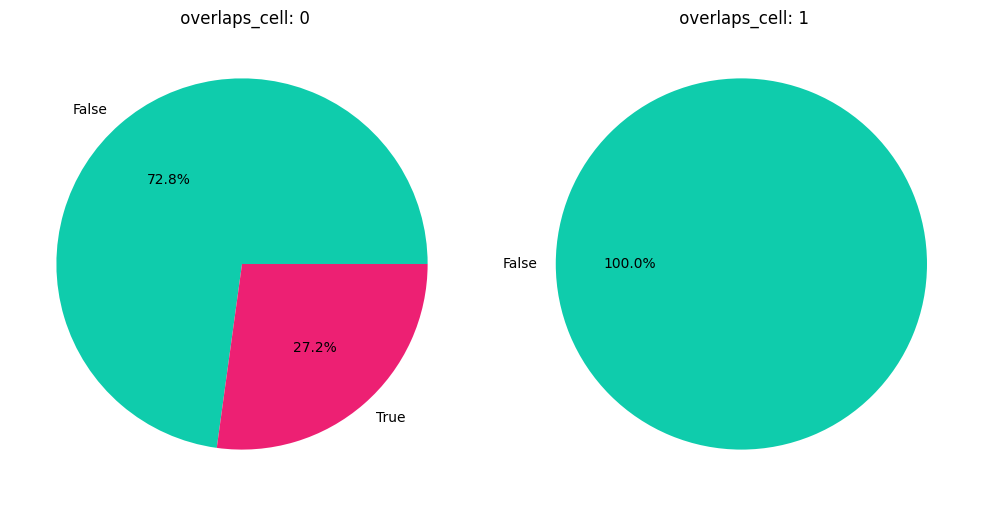

In [77]:
troutpy.pl.pie(sdata, groupby="extracellular",group_key='overlaps_cell')

<Figure size 500x500 with 0 Axes>

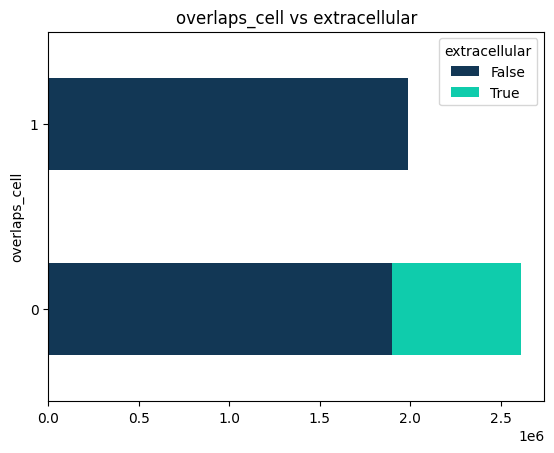

In [78]:
troutpy.pl.crosstab(sdata,yvar='extracellular',xvar='overlaps_cell',normalize=False, cmap='troutpy',kind='barh',stacked=True)

In [79]:
sdata['transcripts']

,x,y,z,feature_name,cell_id,qv,fov_name,overlaps_nucleus,transcript_id,nucleus_distance,xy,closest_cell_type,cosine_similarity,assignment_score,overlaps_cell,match_cell_signature,extracellular
npartitions=1,,,,,,,,,,,,,,,,,
0,float32,float32,float32,category[known],string,float32,string,uint8,uint64,float32,string,string,float64,float64,uint8,bool,bool
4600229,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...


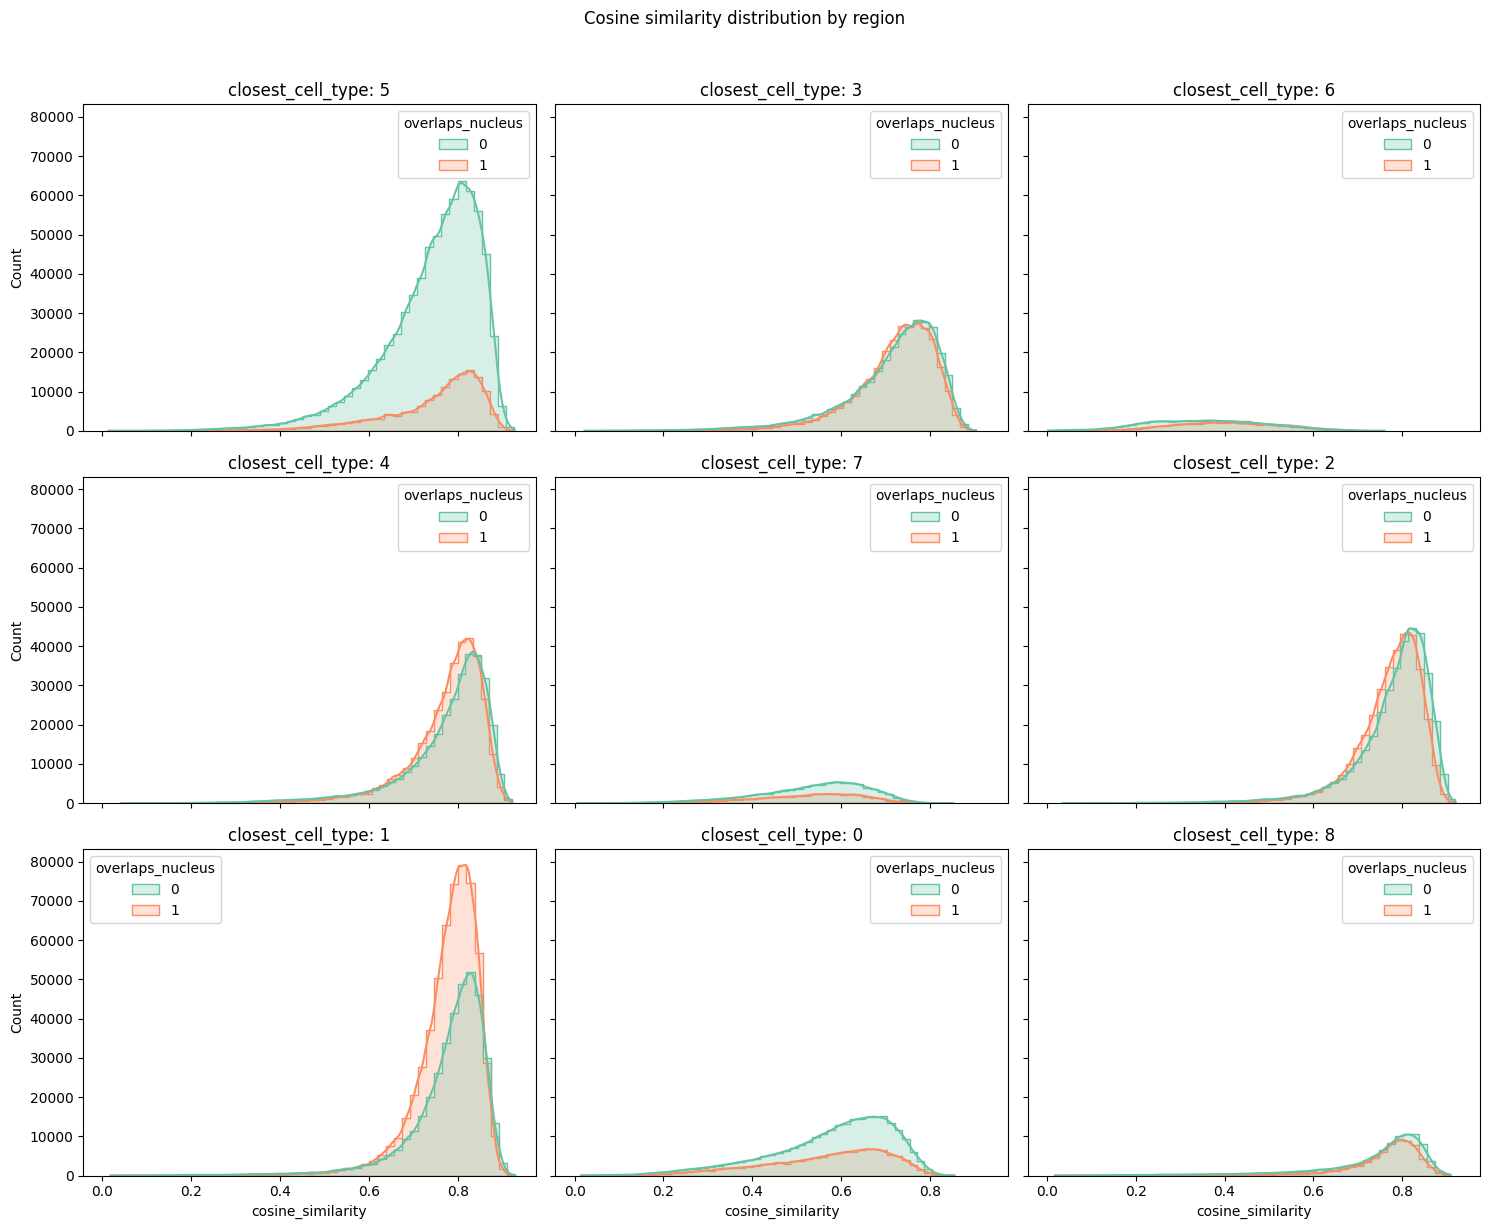

In [80]:
troutpy.pl.histogram(
    sdata,
    x="cosine_similarity",
    hue="overlaps_nucleus",
    group_key="closest_cell_type",
    title="Cosine similarity distribution by region",
    save=False,
    bins=50,
    kde=True,
    palette="Set2"
)


## Quantify exRNa

In [81]:
import numpy as np
gen=np.unique(sdata['transcripts']['feature_name'].compute())
control_codewords = [g for g in gen if 'Con' in g ]

troutpy.tl.quantify_overexpression(
    sdata,layer="transcripts",codeword_key="feature_name",
    control_codewords=control_codewords,gene_key="feature_name",
    percentile_threshold=99.99)

False


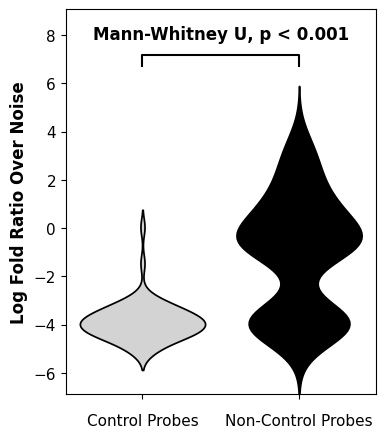

In [82]:
troutpy.pl.logfoldratio_over_noise(sdata,test_method="auto")

In [61]:
import pandas as pd
pd.crosstab(sdata['xrna_metadata'].var['p_value_Poisson']<0.0005,sdata['xrna_metadata'].var['control_probe'])

control_probe,False,True
p_value_Poisson,,
False,21,6
True,459,55


# Clustering extracellular

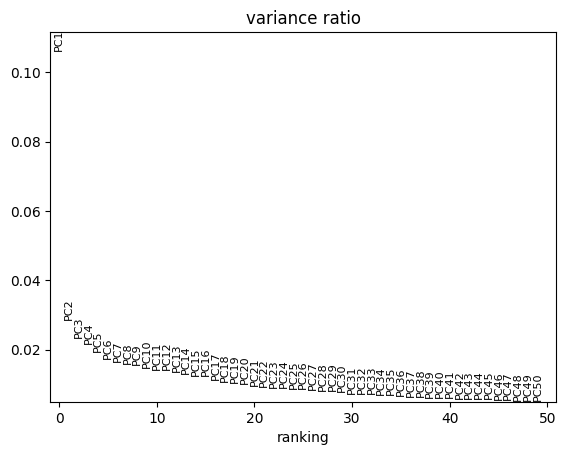

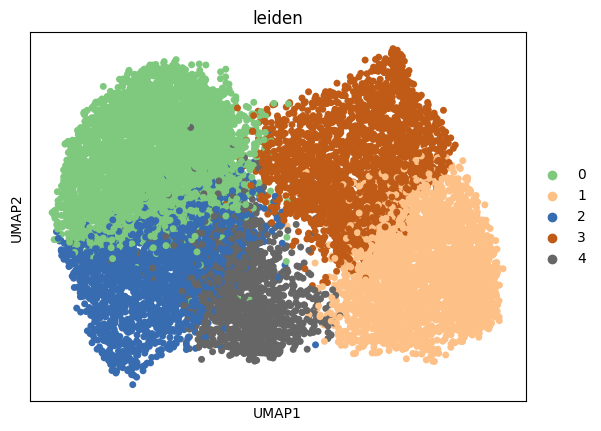

In [83]:
troutpy.pp.aggregate_extracellular_transcripts(sdata,
    layer = "transcripts",
    gene_key = "feature_name",
    method = "bin", square_size=15
)
adata=sdata.tables['segmentation_free_table']
adata.raw = adata
sc.pp.filter_genes(adata, min_cells=2)
sc.pp.filter_cells(adata, min_genes=3)
sc.pp.filter_cells(adata, min_counts=10)

adata.layers["raw"] = adata.X.copy()
sc.pp.normalize_total(adata)
# Logarithmize the data
sc.pp.log1p(adata)
#pca
sc.tl.pca(adata)
sc.pl.pca_variance_ratio(adata, n_pcs=50)
# neighbors
sc.pp.neighbors(adata,n_neighbors=30)
sc.tl.umap(adata)
sc.tl.leiden(adata, key_added="leiden",resolution=0.7)
sc.pl.umap(adata,color='leiden',palette='Accent',s=100)

[<Axes: title={'center': 'leiden'}, xlabel='spatial1', ylabel='spatial2'>]

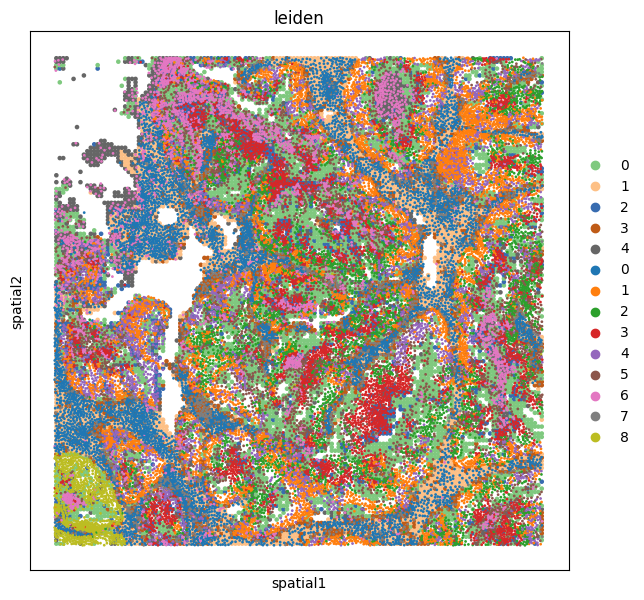

In [87]:
fig,ax=plt.subplots(figsize=(7,7))
sc.pl.spatial(adata, color="leiden", spot_size=20,show=False,ax=ax,marker='s')
#fig,ax=plt.subplots(figsize=(7,7))
sc.pl.spatial(sdata['table'], color="leiden", spot_size=12,show=False,ax=ax,marker='*',outline_width=(0.8, 0.05),outline_color='black')

[<Axes: title={'center': 'leiden'}, xlabel='spatial1', ylabel='spatial2'>]

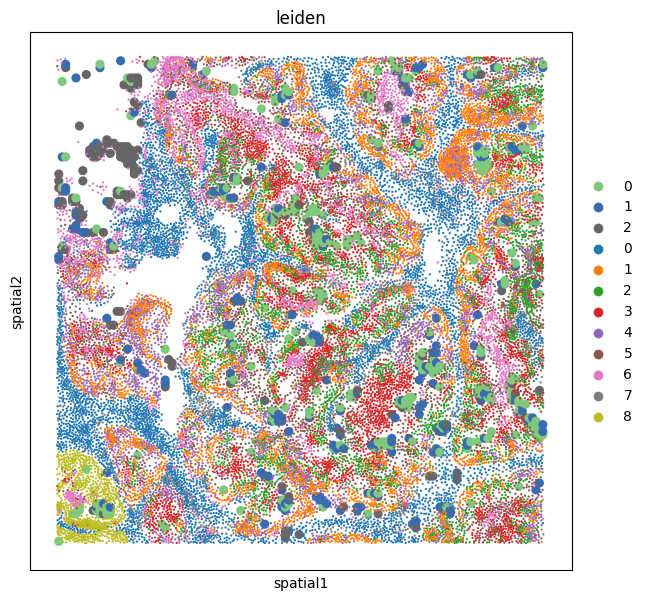

In [66]:
fig,ax=plt.subplots(figsize=(7,7))
sc.pl.spatial(adata, color="leiden", spot_size=40,show=False,ax=ax,marker='s')
#fig,ax=plt.subplots(figsize=(7,7))
sc.pl.spatial(sdata['table'], color="leiden", spot_size=10,show=False,ax=ax,marker='*',outline_width=(0.8, 0.05),outline_color='black')

# Test diffussion

In [ ]:
troutpy.pp.filter_xrna(sdata,min_logfoldratio_over_noise=0)

In [25]:
import warnings

import numpy as np
import pandas as pd
import scanpy as sc
import spatialdata as sd
from sklearn.neighbors import KDTree
from spatialdata import SpatialData
from tqdm import tqdm

def compute_source_score(
    sdata: SpatialData,
    layer: str = "transcripts",
    gene_key: str = "feature_name",
    coord_keys: list = None,  # type: ignore
    lambda_decay: float = 0.1,
    copy: bool = False,
    celltype_key: str = "cell type",
):
    """
    Computes the probabilities of each extracellular transcript originating from a specific cell.

    Parameters
    ----------
    sdata
        The input spatial data object.
    layer
        The layer in `sdata.points` containing the transcript data. Default is 'transcripts'.
    gene_key
        Column name in the transcript data representing gene identifiers. Default is 'feature_name'.
    xcoord, ycoord
        Column names for spatial coordinates of transcripts and cell centroids.
    lambda_decay
        The exponential decay factor for distances.
    copy
        If True, returns a modified copy of the SpatialData object.
    celltype_key
        Key for cell type annotations in the cell table.

    Returns
    -------
    sdata
        Updated SpatialData object with source scores added in sdata.tables['source_score'], including distance to closest cell
    """
    if coord_keys is None:
        coord_keys = ["x", "y"]
    xcoord = coord_keys[0]
    ycoord = coord_keys[1]

    transcripts = sdata.points[layer].compute()
    cells = sdata["table"].to_df()
    coord_cells = sdata["table"].obsm["spatial"]
    cell_types = sdata["table"].obs[celltype_key]
    all_cell_types = cell_types.unique()

    # Ensure necessary columns exist
    required_cols = [xcoord, ycoord, gene_key]
    for col in required_cols:
        if col not in transcripts.columns and col not in cells.columns:
            raise ValueError(f"Required column '{col}' is missing.")

    # Filter for extracellular transcripts only
    extracellular_transcripts = transcripts[transcripts["extracellular"]]
    probabilities_table = pd.DataFrame(0, index=extracellular_transcripts.index, columns=all_cell_types, dtype=float)

    # Precompute KDTree for all cell coordinates
    closet_cell_table = pd.DataFrame(0, index=extracellular_transcripts.index, columns=["closest_cell", "closest_celltype", "distance"])

    # Process each gene
    for gene in tqdm(cells.columns.unique(), desc="Processing genes"):
        # Filter transcripts and cells for the current gene
        gene_transcripts = extracellular_transcripts[extracellular_transcripts[gene_key] == gene]

        gene_mask = cells[gene] > 0  # Mask for cells expressing the gene
        if not gene_mask.any() or gene_transcripts.empty:
            continue
        transcript_coords = gene_transcripts[[xcoord, ycoord]].to_numpy()
        gene_cells = cells.loc[gene_mask]
        coord_cells_filt = coord_cells[gene_mask]
        cell_types_filt = cell_types[gene_mask]

        # Compute distances between transcripts and filtered cells
        kdtree = KDTree(coord_cells_filt)
        distances, cell_indices = kdtree.query(transcript_coords, k=len(coord_cells_filt))

        # compute_min_dist
        distances_min = np.min(distances, axis=1)
        distances_idx = cell_indices[:, 0]
        cell_id_min = gene_cells.index[distances_idx]
        cell_type_min = cell_types_filt[distances_idx]

        # Get the gene-specific expression values
        cell_exprs = gene_cells[gene].to_numpy()

        # Compute exponential decay scores
        exp_decay = np.exp(-lambda_decay * distances)
        scores = exp_decay * cell_exprs[cell_indices]

        # Aggregate scores by cell type
        for i, transcript_idx in enumerate(gene_transcripts.index):
            cell_indices_i = cell_indices[i]
            scores_i = scores[i]
            types_i = cell_types_filt.iloc[cell_indices_i].to_numpy()

            # add min_distance
            closet_cell_table.loc[transcript_idx, "distance"] = distances_min[i]
            closet_cell_table.loc[transcript_idx, "closest_cell"] = cell_id_min[i]
            closet_cell_table.loc[transcript_idx, "closest_celltype"] = cell_type_min[i]
            for cell_type in all_cell_types:
                probabilities_table.loc[transcript_idx, cell_type] = scores_i[types_i == cell_type].sum()

    # We format all probabilieies as an anndata, stored in sdata.tables['source_score']
    prob_table = sc.AnnData(probabilities_table)
    prob_table.obs[gene_key] = list(extracellular_transcripts[gene_key])
    prob_table.obs["distance"] = list(closet_cell_table["distance"].astype(float))
    #prob_table.obs["feature_name"] = list(closet_cell_table["feature_name"].astype(str))
    prob_table.obs["closest_cell"] = list(closet_cell_table["closest_cell"].astype(str))
    prob_table.obs["closest_celltype"] = list(closet_cell_table["closest_celltype"].astype(str))

    prob_table.obsm["spatial"] = extracellular_transcripts[[xcoord, ycoord]].to_numpy()
    sdata.tables["source_score"] = prob_table
    return sdata.copy() if copy else None


In [ ]:
from tqdm import tqdm
compute_source_score(sdata, layer="transcripts", gene_key="feature_name", lambda_decay=0.1, copy=False, celltype_key="leiden")

Processing genes:   9%|▉         | 36/379 [25:59<3:31:27, 36.99s/it]

In [ ]:
troutpy.tl.assess_diffussion( sdata, gene_key= "feature_name", distance_key= "distance")

In [67]:
troutpy.tl.extracellular_enrichment(sdata)

In [68]:
troutpy.tl.spatial_variability(sdata, gene_key="feature_name", n_neighbors=10, square_size=20)

Using precomputed segmentation free table


In [69]:
troutpy.pp.aggregate_extracellular_transcripts(sdata,square_size = 8)
troutpy.tl.in_out_correlation(sdata,n_neighbors=20)

In [ ]:
outpath = "/media/sergio/Meninges/troutpy/xenium_mouse_crc_processed.zarr"
sdata.write(outpath,overwrite=True)

INFO     The SpatialData object is not self-contained (i.e. it contains some elements that are Dask-backed from    
         locations outside /media/sergio/Meninges/troutpy/xenium_mouse_colon_roi_processed.zarr). Please see the   
         documentation of `is_self_contained()` to understand the implications of working with SpatialData objects 
         that are not self-contained.                                                                              
INFO     The Zarr backing store has been changed from None the new file path:                                      
         /media/sergio/Meninges/troutpy/xenium_mouse_colon_roi_processed.zarr                                      


## Exploration of results

In [71]:
troutpy.pl.diffusion_results(sdata, y_col='-log_ks_pval',y_logscale=True)

ValueError: Could not interpret value `mean_displacement` for `x`. An entry with this name does not appear in `data`.

<Figure size 1000x600 with 0 Axes>

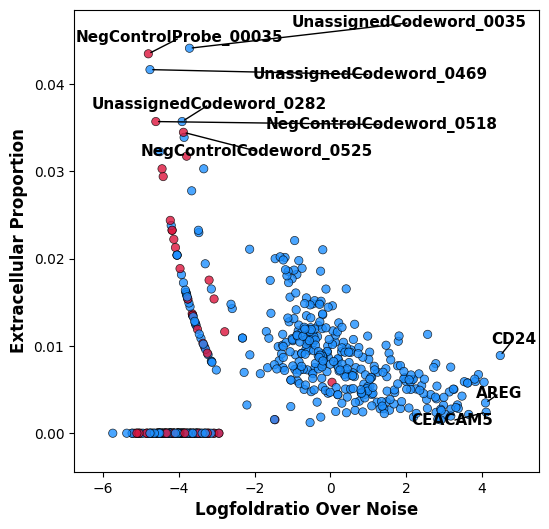

In [72]:
troutpy.pl.metric_scatter(sdata,
x_metric="logfoldratio_over_noise",
y_metric="extracellular_proportion",
label_top_n_x=3,label_top_n_y=6)

In [73]:
troutpy.tl.compare_intra_extra_distribution(sdata,copy=False,n_bins=20)

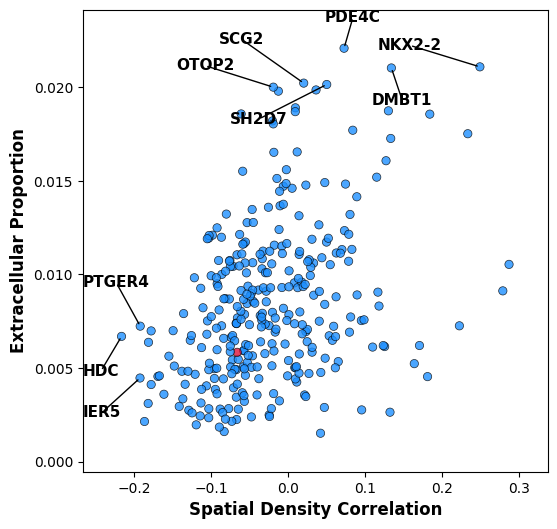

In [74]:
troutpy.pl.metric_scatter(sdata,
x_metric="spatial_density_correlation",
y_metric="extracellular_proportion",
label_top_n_x=0,label_top_n_y=6,label_bottom_n_x=3)

In [75]:
bottom_genes=sdata['xrna_metadata'].var.sort_values(by='spatial_density_correlation')['spatial_density_correlation'].keys()[0:6]
top_genes=sdata['xrna_metadata'].var.sort_values(by='spatial_density_correlation',ascending=False)['spatial_density_correlation'].keys()[0:6]

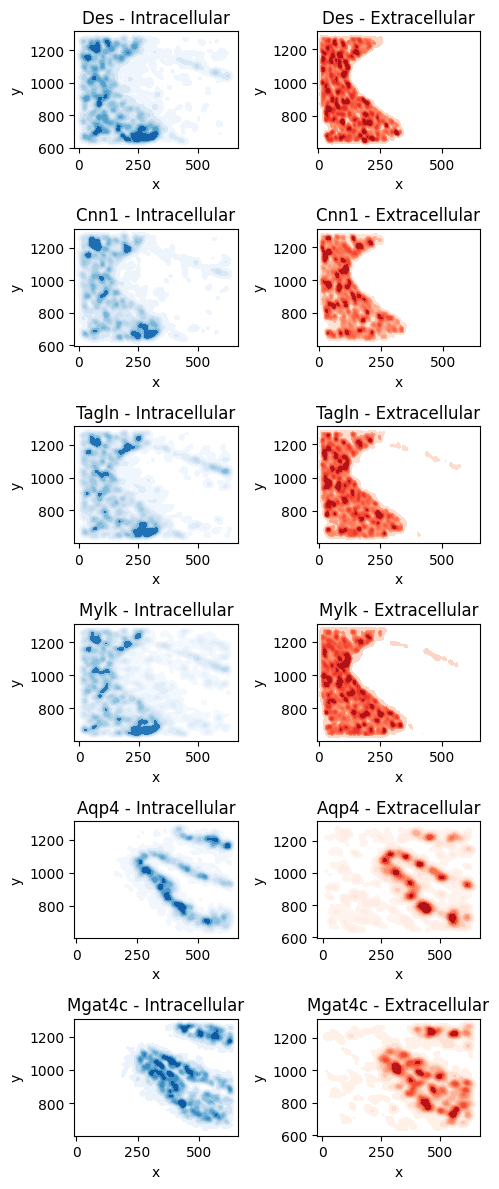

In [76]:
troutpy.pl.intra_extra_density(
    sdata, top_genes, layer="transcripts", gene_key="feature_name", coord_keys=["x", "y"],
    intra_kde_kwargs = {"fill": True, "cmap": "Blues", "thresh": 0.05,"bw_adjust":0.3}, 
    extra_kde_kwargs = {"fill": True, "cmap": "Reds", "thresh": 0.05,"bw_adjust":0.3},figsize=(5,12)
)

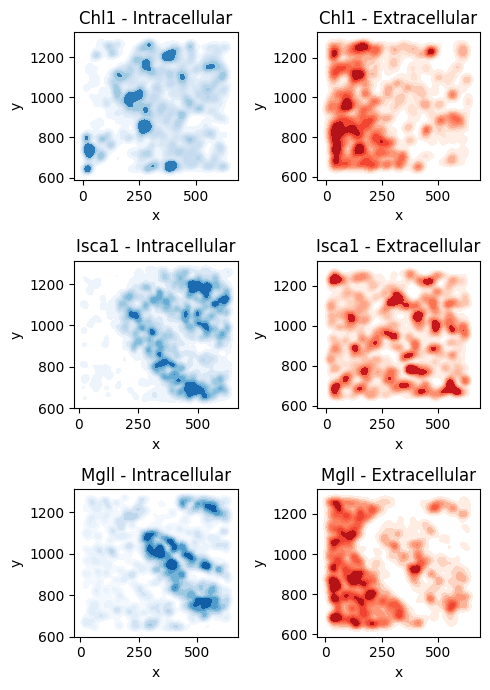

In [73]:
troutpy.pl.intra_extra_density(
    sdata, bottom_genes, layer="transcripts", gene_key="feature_name", coord_keys=["x", "y"],
    intra_kde_kwargs = {"fill": True, "cmap": "Blues", "thresh": 0.05,"bw_adjust":0.3}, 
    extra_kde_kwargs = {"fill": True, "cmap": "Reds", "thresh": 0.05,"bw_adjust":0.3},figsize=(5,7)
)

In [77]:
troutpy.pp.filter_xrna(sdata,min_logfoldratio_over_noise=3)

In [78]:
troutpy.tl.compare_intra_extra_distribution(sdata,copy=False)

In [68]:
gen=sdata['xrna_metadata'].var.sort_values(by='intracellular_proportion',ascending=True).index[0:4]
sdata['xrna_metadata'].var.sort_values(by='intracellular_proportion',ascending=True)

,count,logfoldratio_over_noise,p_value_Poisson,intracellular_proportion,extracellular_proportion,logfoldratio_extracellular,moran_I,moran_pval_norm,moran_var_norm,moran_pval_norm_fdr_bh,in_out_spearmanR,in_out_pvalue,centroid_shift_distance,spatial_density_correlation,spatial_js_divergence
Des,1718466,5.372709,0.0,0.420576,0.579424,-1.527242,0.794840,0.0,0.000002,0.0,0.559565,0.0,235.874054,0.898087,0.038660
Rgs5,1292465,5.087829,0.0,0.486830,0.513170,-1.259523,0.767295,0.0,0.000002,0.0,0.572803,0.0,114.919647,0.896741,0.045251
Myh11,2954152,5.914489,0.0,0.500571,0.499429,-1.204548,0.803042,0.0,0.000002,0.0,0.614265,0.0,175.079300,0.895307,0.043182
Cnn1,1095387,4.922385,0.0,0.514510,0.485490,-1.148774,0.752762,0.0,0.000002,0.0,0.605094,0.0,132.244095,0.919385,0.027027
Tagln,1883852,5.464596,0.0,0.519607,0.480393,-1.128365,0.776630,0.0,0.000002,0.0,0.617004,0.0,165.001114,0.906204,0.035734
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Pglyrp1,491612,4.121212,0.0,0.860886,0.139114,0.615838,0.403058,0.0,0.000002,0.0,0.478195,0.0,135.951080,0.964150,0.015897
5330417C22Rik,588109,4.300434,0.0,0.862925,0.137075,0.632968,0.400191,0.0,0.000002,0.0,0.506649,0.0,118.910728,0.962626,0.014965
Cldn4,175347,3.090289,0.0,0.863494,0.136506,0.637783,0.333075,0.0,0.000002,0.0,0.370564,0.0,71.764809,0.955798,0.016547
Ptprn2,200592,3.224795,0.0,0.870872,0.129128,0.701861,0.251532,0.0,0.000002,0.0,0.338198,0.0,142.429138,0.942986,0.017906


In [61]:
gen=sdata['xrna_metadata'].var.sort_values(by='spatial_density_correlation',ascending=True).index[0:4]
sdata['xrna_metadata'].var.sort_values(by='spatial_density_correlation',ascending=True)

,count,logfoldratio_over_noise,p_value_Poisson,intracellular_proportion,extracellular_proportion,logfoldratio_extracellular,moran_I,moran_pval_norm,moran_var_norm,moran_pval_norm_fdr_bh,in_out_spearmanR,in_out_pvalue,centroid_shift_distance,spatial_density_correlation,spatial_js_divergence
Mgll,435836,4.000788,0.0,0.758866,0.241134,-0.060361,0.489629,0.0,0.000002,0.0,0.340680,0.0,63.303387,0.636961,0.051766
Bgn,560456,4.252273,0.0,0.816630,0.183370,0.286846,0.344240,0.0,0.000002,0.0,0.300215,0.0,73.513901,0.767284,0.032882
Dpt,390914,3.892010,0.0,0.735840,0.264160,-0.182376,0.390313,0.0,0.000002,0.0,0.308351,0.0,163.018616,0.782256,0.039425
Chl1,215006,3.294188,0.0,0.652428,0.347572,-0.577102,0.388354,0.0,0.000002,0.0,0.201248,0.0,106.977654,0.782540,0.035466
Sfrp1,170556,3.062586,0.0,0.805794,0.194206,0.216077,0.255329,0.0,0.000002,0.0,0.253969,0.0,113.822319,0.791838,0.036108
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Oit1,1867761,5.456018,0.0,0.860657,0.139343,0.613923,0.492231,0.0,0.000002,0.0,0.667311,0.0,143.438889,0.969365,0.012514
Tfcp2l1,1468150,5.215280,0.0,0.830938,0.169062,0.385460,0.498740,0.0,0.000002,0.0,0.631032,0.0,71.777977,0.969914,0.010797
Cldn2,611131,4.338833,0.0,0.881705,0.118295,0.801840,0.429227,0.0,0.000002,0.0,0.580331,0.0,75.898804,0.972266,0.016874
Aqp4,177059,3.100005,0.0,0.809832,0.190168,0.242085,0.362197,0.0,0.000002,0.0,0.434927,0.0,17.113632,0.972980,0.019523


Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x7f53b1ccc5b0>>
Traceback (most recent call last):
  File "/home/sergio/.local/lib/python3.10/site-packages/ipykernel/ipkernel.py", line 775, in _clean_thread_parent_frames
    def _clean_thread_parent_frames(
KeyboardInterrupt: 


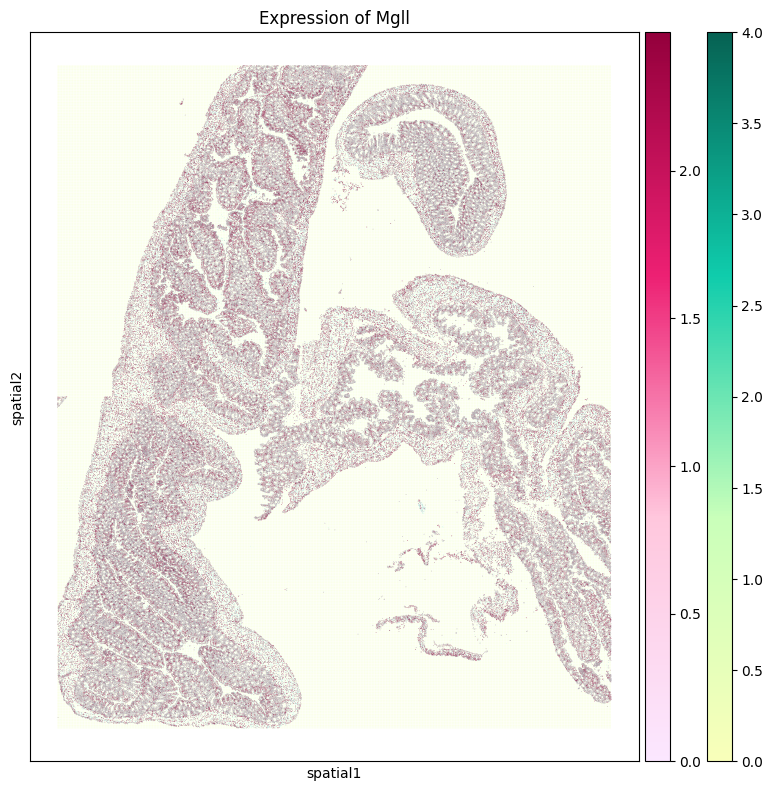

In [66]:
troutpy.pl.spatial_inout_expression(sdata,'Bgn',spot_size_cells=6,spot_size_extra=4)

## Signature analysis

In [ ]:
xenium_path_cropped = "/media/sergio/Meninges/troutpy/xenium_mouse_colon_roi_processed.zarr"
sdata=sd.read_zarr(xenium_path_cropped)

In [ ]:
troutpy.pp.aggregate_extracellular_transcripts(sdata,
    layer = "transcripts",
    gene_key = "feature_name",
    method = "bin", square_size=10,
)

In [153]:
adata=sdata.tables['segmentation_free_table']
adata.raw = adata
sc.pp.filter_genes(adata, min_cells=20)
sc.pp.filter_cells(adata, min_genes=10)
sc.pp.filter_cells(adata, min_counts=200)


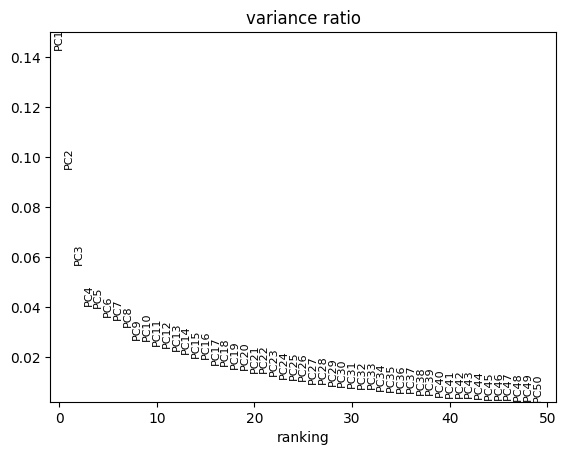

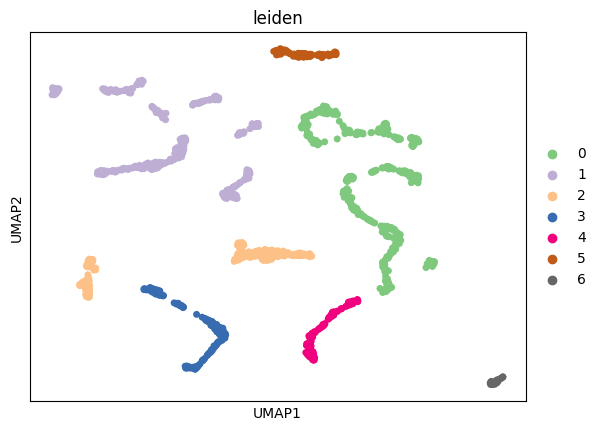

In [156]:

adata.layers["raw"] = adata.X.copy()
sc.pp.normalize_total(adata)
# Logarithmize the data
sc.pp.log1p(adata)
#pca
sc.tl.pca(adata)
sc.pl.pca_variance_ratio(adata, n_pcs=50)
# neighbors
sc.pp.neighbors(adata,n_neighbors=30)
sc.tl.umap(adata)
sc.tl.leiden(adata, key_added="leiden",resolution=0.01)
sc.pl.umap(adata,color='leiden',palette='Accent',s=100)

[<Axes: title={'center': 'leiden'}, xlabel='spatial1', ylabel='spatial2'>]

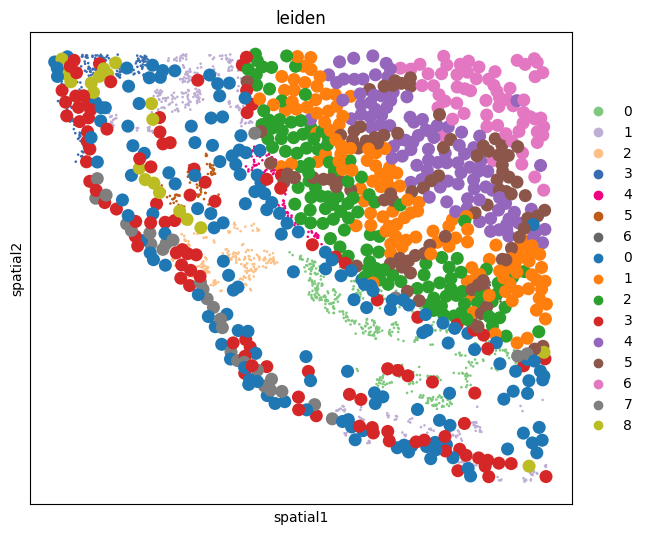

In [157]:
fig,ax=plt.subplots(figsize=(7,7))
sc.pl.spatial(adata, color="leiden", spot_size=2,show=False,ax=ax,marker='s')
#fig,ax=plt.subplots(figsize=(7,7))
sc.pl.spatial(sdata['table'], color="leiden", spot_size=10,show=False,ax=ax,marker='*',outline_width=(0.8, 0.05),outline_color='black')

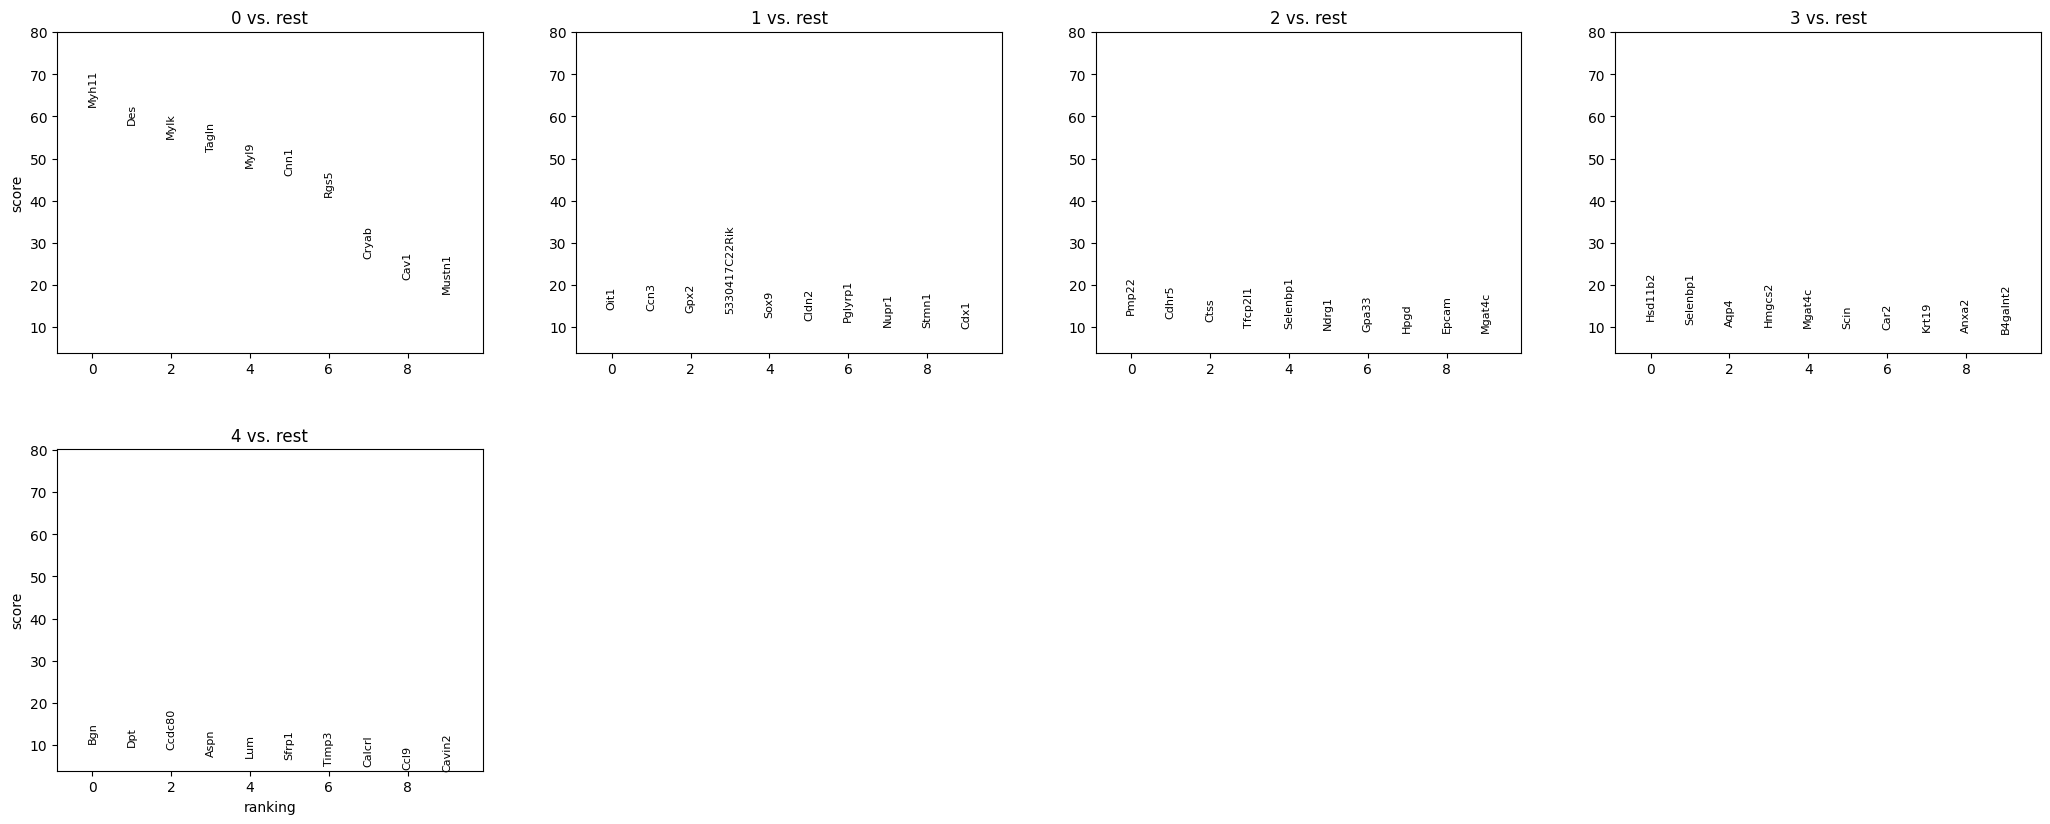

In [105]:
sc.tl.dendrogram(adata,groupby='leiden')
sc.tl.rank_genes_groups(adata,groupby='leiden')
sc.pl.rank_genes_groups(adata,groupby='leiden',n_genes=10)

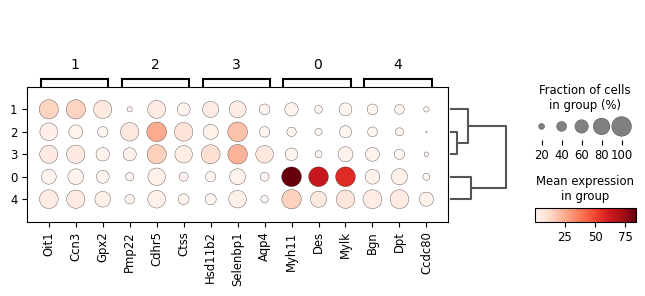

In [106]:
sc.pl.rank_genes_groups_dotplot(adata,groupby='leiden',n_genes=3)

In [107]:
troutpy.tl.latent_factor(sdata,method='NMF',layer='segmentation_free_table', n_components=10)

In [108]:
troutpy.tl.apply_exrna_factors_to_cells(sdata, extracellular_layer = "segmentation_free_table", cellular_layer='table')

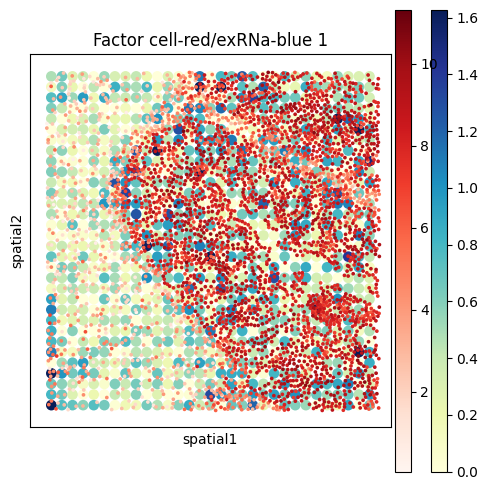

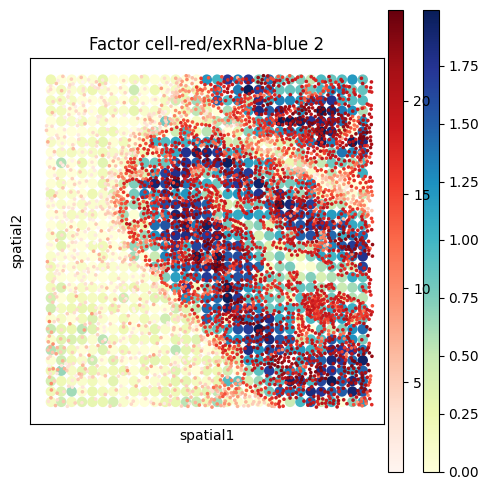

In [119]:
troutpy.pl.paired_nmf_factors(sdata,layer='segmentation_free_table',spot_size_exrna=20,spot_size_cells=7, figsize=(5, 5), n_factors=2)

[<Axes: title={'center': 'NNAT'}, xlabel='spatial1', ylabel='spatial2'>]

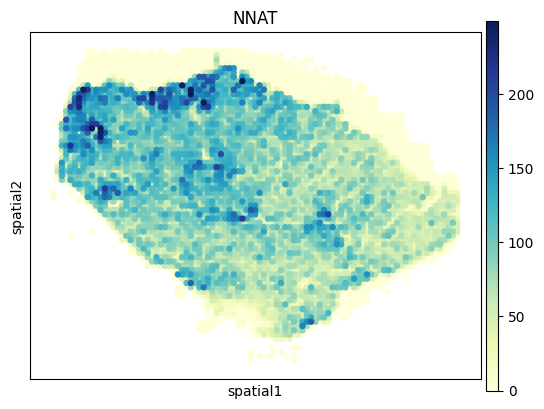

In [61]:
gene='NNAT'
sc.pl.spatial(sdata['segmentation_free_table'],color=gene,cmap='YlGnBu',show=False,spot_size=150,vmax='p99.9')

[<Axes: title={'center': 'MT-CO2'}, xlabel='spatial1', ylabel='spatial2'>]

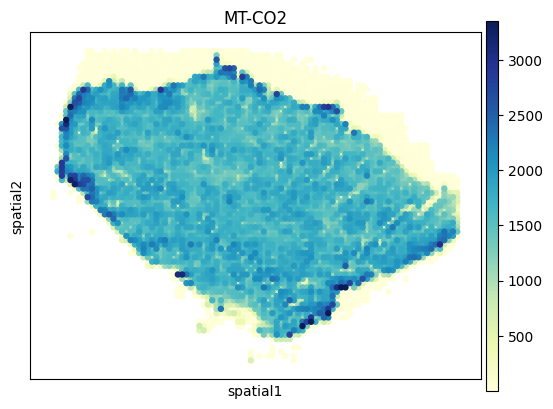

In [52]:
gene='MT-CO2'
sc.pl.spatial(sdata['segmentation_free_table'],color=gene,cmap='YlGnBu',show=False,spot_size=150,vmax='p99.9')

In [ ]:
sdata['xrna_metadata'].var.sort_values(by='moran_I',ascending=False).head(10)

In [35]:
troutpy.pl.nmf_gene_contributions(sdata, nmf_adata_key="segmentation_free_table", vmin=0.0, vmax=0.02, save=False, figsize=(4, 5))

KeyError: 'H_nmf'